
# Problem Statement : Analysing global sales to identify the most profitable regions|

In [1]:
import pandas as pd 
import numpy as np

In [2]:
df=pd.read_csv("Global_Ecommerce_Sales.csv")
print("First 5 Records")
df.head()

First 5 Records


,Order ID,Order Date,Country,Product Category,Quantity Sold,Unit Price,Total Sales,Order Status
0,ORD-10001,2025-02-02,United States,Beauty & Personal Care,10,15.07,150.70,Pending
1,ORD-10002,2026-08-04,United Kingdom,Toys & Games,8,20.14,161.12,Completed
2,ORD-10003,2025-09-20,United Kingdom,Electronics,1,732.95,732.95,Cancelled
3,ORD-10004,2025-05-22,China,Electronics,4,995.79,"3,983.16",Pending
4,ORD-10005,2025-02-09,United States,Books & Media,4,19.44,77.76,Pending


In [3]:
df.tail()

,Order ID,Order Date,Country,Product Category,Quantity Sold,Unit Price,Total Sales,Order Status
1996,ORD-11957,2025-10-17,United States,Apparel & Accessories,3,162.30,486.90,Completed
1997,ORD-11958,2025-05-11,China,Home & Kitchen,6,42.90,257.40,Completed
1998,ORD-11959,2025-06-22,India,Toys & Games,8,38.37,306.96,Completed
1999,ORD-11960,2025-11-29,United States,Apparel & Accessories,8,85.88,687.04,Completed
2000,Total,NaN,NaN,NaN,"9,666",NaN,"10,92,214.60",NaN


In [4]:
df.dtypes

Order ID            object
Order Date          object
Country             object
Product Category    object
Quantity Sold       object
Unit Price          object
Total Sales         object
Order Status        object
dtype: object

In [5]:
df.describe()

,Order ID,Order Date,Country,Product Category,Quantity Sold,Unit Price,Total Sales,Order Status
count,2001,1943,1901,1932,1917,1926,1847,1947
unique,1961,599,12,8,13,1792,1784,5
top,ORD-10317,2025-03-22,United States,Electronics,1,31.44,399.54,Completed
freq,4,9,579,266,245,4,4,969


In [6]:
df.shape

(2001, 8)

In [7]:
df.dtypes

Order ID            object
Order Date          object
Country             object
Product Category    object
Quantity Sold       object
Unit Price          object
Total Sales         object
Order Status        object
dtype: object

In [8]:
df.isnull().sum()

Order ID              0
Order Date           58
Country             100
Product Category     69
Quantity Sold        84
Unit Price           75
Total Sales         154
Order Status         54
dtype: int64

In [9]:
# 1. Remove summary row and fix numeric parsing
df = df[df['Order ID'] != 'Total'].copy()

df['Quantity Sold'] = pd.to_numeric(df['Quantity Sold'], errors='coerce')
df['Unit Price'] = pd.to_numeric(df['Unit Price'], errors='coerce')
df['Total Sales'] = pd.to_numeric(
    df['Total Sales'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')

# 2. Recover whichever of the 3 financial fields is missing if the other 2 exist
m_sales = df['Total Sales'].isna() & df['Quantity Sold'].notna() & df['Unit Price'].notna()
df.loc[m_sales, 'Total Sales'] = df.loc[m_sales, 'Quantity Sold'] * df.loc[m_sales, 'Unit Price']

m_price = df['Unit Price'].isna() & df['Total Sales'].notna() & df['Quantity Sold'].notna() & (df['Quantity Sold'] > 0)
df.loc[m_price, 'Unit Price'] = df.loc[m_price, 'Total Sales'] / df.loc[m_price, 'Quantity Sold']

m_qty = df['Quantity Sold'].isna() & df['Total Sales'].notna() & df['Unit Price'].notna() & (df['Unit Price'] > 0)
df.loc[m_qty, 'Quantity Sold'] = df.loc[m_qty, 'Total Sales'] / df.loc[m_qty, 'Unit Price']

# 3. Fill categoricals & drop duplicates
df['Country'] = df['Country'].fillna('Unknown')
df['Product Category'] = df['Product Category'].fillna('Unspecified')
df['Order Status'] = df['Order Status'].fillna('Unknown')
df = df.drop_duplicates(subset=['Order ID'], keep='first')

In [10]:
df.dtypes

Order ID                    object
Order Date          datetime64[ns]
Country                     object
Product Category            object
Quantity Sold              float64
Unit Price                 float64
Total Sales                float64
Order Status                object
dtype: object

In [11]:
df.duplicated().sum()

np.int64(0)

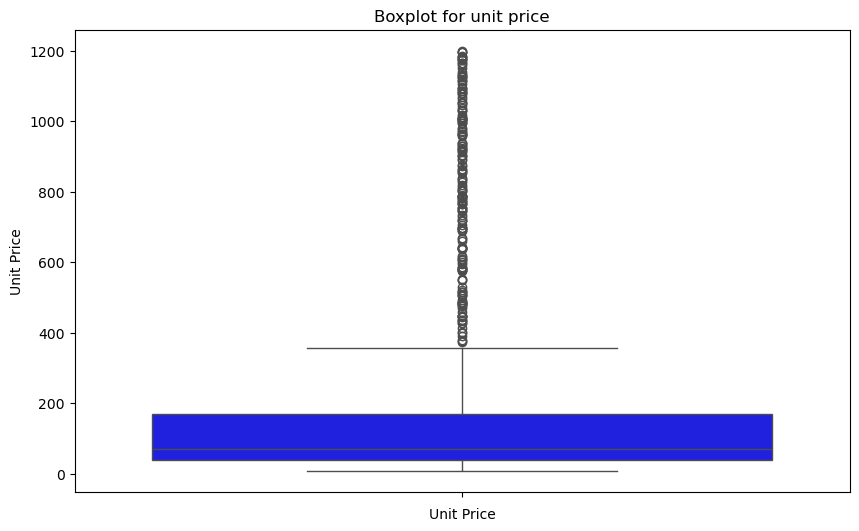

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,6))
sns.boxplot(df['Unit Price'],color='blue')
plt.title('Boxplot for unit price')
plt.xlabel("Unit Price")
plt.show()


In [13]:
Q1 = df['Unit Price'].quantile(0.25)
Q3 = df['Unit Price'].quantile(0.75)
IQR = Q3-Q1
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR



In [14]:
outliers_count = ((df['Unit Price'] < lower_bound) | (df['Unit Price'] > upper_bound)).sum()
print(f"Number of outliers detected in Unit Price: {outliers_count}")

Number of outliers detected in Unit Price: 194


In [15]:
df['Unit Price'] = df['Unit Price'].clip(lower=lower_bound, upper=upper_bound)
print("Outlier successfully capped using IQR")

Outlier successfully capped using IQR


In [16]:
df.isnull().sum()

Order ID              0
Order Date           56
Country               0
Product Category      0
Quantity Sold        83
Unit Price           75
Total Sales         152
Order Status          0
dtype: int64

In [17]:

df = df.dropna(subset=['Order Date', 'Quantity Sold', 'Total Sales'])
df['Order Status'] = df['Order Status'].fillna('Unknown')
print("Missing values after final  cleaning:\n", df.isnull().sum())

Missing values after final  cleaning:
 Order ID            0
Order Date          0
Country             0
Product Category    0
Quantity Sold       0
Unit Price          0
Total Sales         0
Order Status        0
dtype: int64


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

df_model = df.dropna(subset=['Order Date', 'Quantity Sold', 'Unit Price', 'Total Sales']).copy()
df_model['Year'] = df_model['Order Date'].dt.year
df_model['Month'] = df_model['Order Date'].dt.month
df_model['DayOfWeek'] = df_model['Order Date'].dt.dayofweek
df_model['Qty_x_Price'] = df_model['Quantity Sold'] * df_model['Unit Price']

features = [
    'Quantity Sold', 'Unit Price', 'Qty_x_Price',
    'Year', 'Month', 'DayOfWeek',
    'Country', 'Product Category', 'Order Status'
]

X = pd.get_dummies(df_model[features], drop_first=True)
y = df_model['Total Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
print(f" R2: {r2_score(y_test, y_pred):.4f}")
print(f" RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

 R2: 0.8808
 RMSE: 261.7020


In [19]:
# Create a comparison DataFrame for the first 10 test samples
comparison_df = pd.DataFrame({
    'Actual Total Sales': y_test.values[:10],
    'Predicted Total Sales': y_pred[:10]
})

print(comparison_df)

   Actual Total Sales  Predicted Total Sales
0              134.19              134.37660
1              232.05              231.56470
2             1181.20             1181.02535
3              109.62              109.57800
4              912.17              910.44565
5              313.15              312.49710
6              714.72              899.20760
7              242.48              243.04485
8              192.15              192.16940
9              424.20              424.85005


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf_model.fit(X_train_scaled, y_train)
y_pred = rf_model.predict(X_test_scaled)

In [22]:
# Scale the entire feature matrix X using the already-fitted scaler
X_scaled = scaler.transform(X)

# Predict total sales for ALL rows in df_model
all_predictions = rf_model.predict(X_scaled)

# Create a DataFrame comparing Actual vs Predicted
full_results_df = df_model.copy()
full_results_df['Predicted Total Sales'] = all_predictions

# Display the first few rows to check
print(full_results_df[['Order ID', 'Total Sales', 'Predicted Total Sales']].head(10))

     Order ID  Total Sales  Predicted Total Sales
0   ORD-10001       150.70              150.79530
1   ORD-10002       161.12              161.14420
2   ORD-10003       732.95              739.46780
3   ORD-10004      3983.16             3914.52000
4   ORD-10005        77.76               77.81290
5   ORD-10006       554.08              553.44390
6   ORD-10007       617.31              617.21630
7   ORD-10008       188.82              188.69025
9   ORD-10010       957.36              956.40490
10  ORD-10011        91.90               91.82355
